In [1]:
# If not installed already
# !pip install torch torchvision pillow tqdm ftfy regex

import torch
import torchvision.transforms as T
from PIL import Image, ImageFilter, ImageDraw
import numpy as np
from tqdm import tqdm


In [3]:
!pip install git+https://github.com/openai/CLIP.git


Defaulting to user installation because normal site-packages is not writeable
  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-5304fpg9
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-5304fpg9
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 8.5 MB/s eta 0:00:00
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369550 sha256=d780b080c7db8aebc955fc1a75f2ff6ed4eeab0a550a48f64f6b00b695b2de6c
  Stored in directory: /tmp/pip-ephem-wheel-cache-9tjk3z7c/wheels/35/3e/df/3d24cbfb3b6a06f17a2bfd7d1138900d4365d9028aa8f6e92f
Successfully built clip
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import clip

device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()

print("Device:", device)


100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 115MiB/s]
/x4/ljiao/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:734: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Device: cuda


In [5]:
def cosine_distance(a, b):
    a = a / a.norm(dim=-1, keepdim=True)
    b = b / b.norm(dim=-1, keepdim=True)
    return 1 - (a @ b.T).item()


In [6]:
def gaussian_blur(img, radius=5):
    return img.filter(ImageFilter.GaussianBlur(radius))

def low_resolution(img, scale=0.25):
    w, h = img.size
    img_small = img.resize((int(w*scale), int(h*scale)), Image.BILINEAR)
    return img_small.resize((w, h), Image.BILINEAR)

def center_crop(img, crop_ratio=0.5):
    w, h = img.size
    cw, ch = int(w*crop_ratio), int(h*crop_ratio)
    left = (w - cw) // 2
    top = (h - ch) // 2
    return img.crop((left, top, left+cw, top+ch)).resize((w, h))

def occlusion(img, occ_ratio=0.3):
    img = img.copy()
    w, h = img.size
    ow, oh = int(w*occ_ratio), int(h*occ_ratio)
    draw = ImageDraw.Draw(img)
    draw.rectangle([0, 0, ow, oh], fill=(0, 0, 0))
    return img


In [7]:
def get_image_embedding(img):
    img_input = preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        emb = model.encode_image(img_input)
    return emb.cpu()

def get_text_embedding(text):
    text_input = clip.tokenize([text]).to(device)
    with torch.no_grad():
        emb = model.encode_text(text_input)
    return emb.cpu()


In [8]:
!pip install datasets


Defaulting to user installation because normal site-packages is not writeable


In [10]:
from datasets import load_dataset

dataset = load_dataset(
    "conceptual_captions",
    split="train[:2000]"   # take only 2k for now
)

print("Total samples:", len(dataset))


Generating validation split: 100%|██████████| 15840/15840 [00:00<00:00, 1103672.53 examples/s]


Total samples: 2000


In [11]:
import pandas as pd
import time

def compute_disagreement_for_sample(sample, max_retries=2):
    url = sample["image_url"]
    caption = sample["caption"]

    img = None
    for _ in range(max_retries):
        img = load_image_from_url(url)
        if img is not None:
            break
        time.sleep(0.1)

    if img is None:
        return None  # skip broken image

    # text embedding once
    E_txt = get_text_embedding(caption)

    def score(image_pil):
        E_img = get_image_embedding(image_pil)
        return cosine_distance(E_img, E_txt)

    out = {
        "image_url": url,
        "caption": caption,
        "d_original": score(img),
        "d_blur": score(gaussian_blur(img)),
        "d_lowres": score(low_resolution(img)),
        "d_crop": score(center_crop(img)),
        "d_occlusion": score(occlusion(img)),
    }
    return out


In [13]:
import requests
from io import BytesIO
from PIL import Image

def load_image_from_url(url, timeout=8):
    try:
        r = requests.get(url, timeout=timeout, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        return Image.open(BytesIO(r.content)).convert("RGB")
    except Exception:
        return None


In [14]:
N = 300  # start small; later increase to 1000+
rows = []
skipped = 0

for i in tqdm(range(N)):
    r = compute_disagreement_for_sample(dataset[i])
    if r is None:
        skipped += 1
        continue
    rows.append(r)

df = pd.DataFrame(rows)
print("Processed:", len(df), "Skipped:", skipped)
df.head()


100%|██████████| 300/300 [03:52<00:00,  1.29it/s]

Processed: 207 Skipped: 93


,image_url,caption,d_original,d_blur,d_lowres,d_crop,d_occlusion
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station,0.724609,0.737549,0.732666,0.739746,0.721924
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...,0.674316,0.724609,0.696289,0.666260,0.660889
2,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...,0.687256,0.718750,0.726562,0.713867,0.685547
3,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .,0.690186,0.856079,0.764771,0.731445,0.686035
4,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...,0.702393,0.713135,0.698242,0.720215,0.704834


In [15]:
import pandas as pd

df["delta_blur"] = df["d_blur"] - df["d_original"]
df["delta_lowres"] = df["d_lowres"] - df["d_original"]
df["delta_crop"] = df["d_crop"] - df["d_original"]
df["delta_occlusion"] = df["d_occlusion"] - df["d_original"]

df[["d_original","d_blur","d_lowres","d_crop","d_occlusion",
    "delta_blur","delta_lowres","delta_crop","delta_occlusion"]].head()


,d_original,d_blur,d_lowres,d_crop,d_occlusion,delta_blur,delta_lowres,delta_crop,delta_occlusion
0,0.724609,0.737549,0.732666,0.739746,0.721924,0.012939,0.008057,0.015137,-0.002686
1,0.674316,0.724609,0.696289,0.666260,0.660889,0.050293,0.021973,-0.008057,-0.013428
2,0.687256,0.718750,0.726562,0.713867,0.685547,0.031494,0.039307,0.026611,-0.001709
3,0.690186,0.856079,0.764771,0.731445,0.686035,0.165894,0.074585,0.041260,-0.004150
4,0.702393,0.713135,0.698242,0.720215,0.704834,0.010742,-0.004150,0.017822,0.002441


In [16]:
delta_cols = ["delta_blur","delta_lowres","delta_crop","delta_occlusion"]

summary = pd.DataFrame({
    "mean_delta": df[delta_cols].mean(),
    "median_delta": df[delta_cols].median(),
    "frac_increased": (df[delta_cols] > 0).mean(),
    "frac_decreased": (df[delta_cols] < 0).mean(),
}).sort_values("mean_delta", ascending=False)

summary


,mean_delta,median_delta,frac_increased,frac_decreased
delta_blur,0.031108,0.028320,0.898551,0.101449
delta_lowres,0.010543,0.009033,0.782609,0.207729
delta_crop,0.008508,0.005127,0.570048,0.429952
delta_occlusion,0.001733,0.001465,0.608696,0.367150


In [17]:
from scipy.stats import ttest_1samp

for c in delta_cols:
    t, p = ttest_1samp(df[c].values, 0.0)
    print(f"{c:15s} mean={df[c].mean():+.4f}  p={p:.3e}")


delta_blur      mean=+0.0311  p=1.009e-35
delta_lowres    mean=+0.0105  p=1.342e-19
delta_crop      mean=+0.0085  p=7.712e-06
delta_occlusion mean=+0.0017  p=5.591e-04


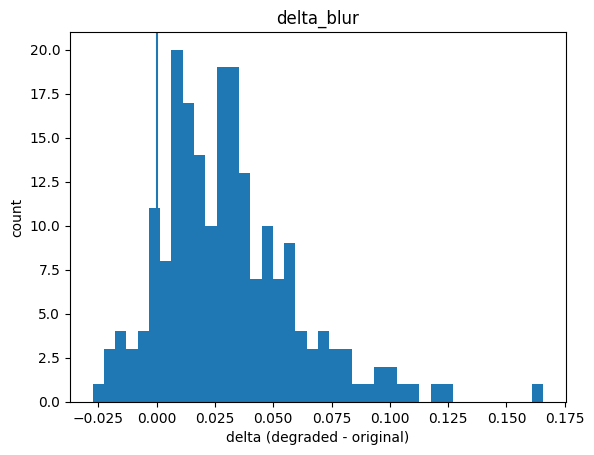

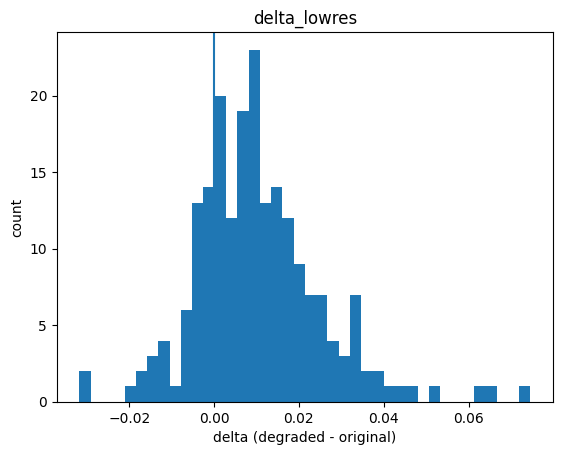

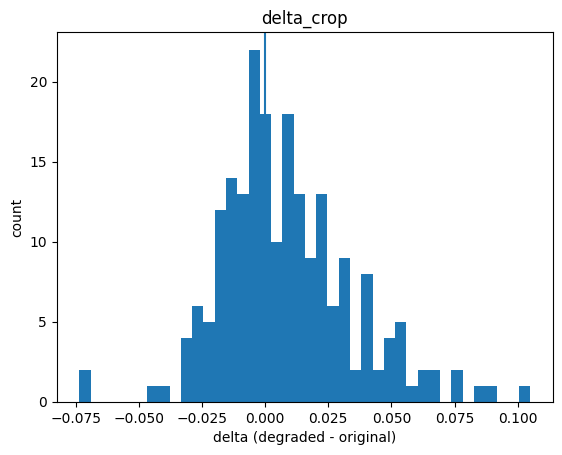

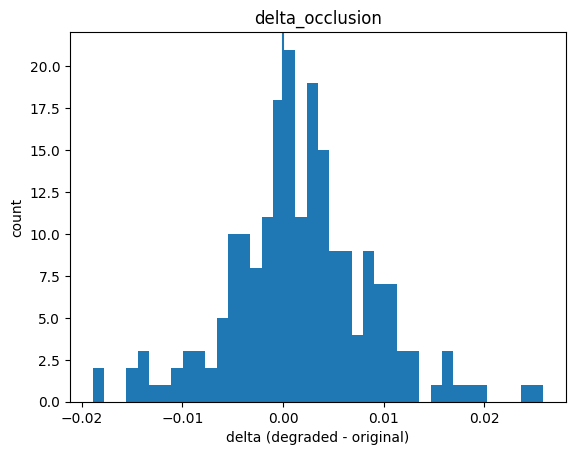

In [18]:
import matplotlib.pyplot as plt

for c in delta_cols:
    plt.figure()
    plt.hist(df[c].values, bins=40)
    plt.title(c)
    plt.xlabel("delta (degraded - original)")
    plt.ylabel("count")
    plt.axvline(0)
    plt.show()


In [20]:
from PIL import Image

def low_resolution(img, scale=0.25, min_size=8):
    w, h = img.size
    new_w = max(min_size, int(w * scale))
    new_h = max(min_size, int(h * scale))

    # If original image is smaller than min_size, just return original
    if w < min_size or h < min_size:
        return img

    img_small = img.resize((new_w, new_h), Image.BILINEAR)
    return img_small.resize((w, h), Image.BILINEAR)


In [21]:
def center_crop(img, crop_ratio=0.5, min_crop=8):
    w, h = img.size
    cw = max(min_crop, int(w * crop_ratio))
    ch = max(min_crop, int(h * crop_ratio))

    # If image too small, return original
    if w < min_crop or h < min_crop:
        return img

    left = max(0, (w - cw) // 2)
    top = max(0, (h - ch) // 2)
    right = min(w, left + cw)
    bottom = min(h, top + ch)

    cropped = img.crop((left, top, right, bottom))
    return cropped.resize((w, h), Image.BILINEAR)


In [22]:
target_processed = 500
rows = []
skipped = 0
i = 0

while len(rows) < target_processed and i < len(dataset):
    r = compute_disagreement_for_sample(dataset[i])
    if r is None:
        skipped += 1
    else:
        rows.append(r)
    i += 1

df = pd.DataFrame(rows)
print("Collected:", len(df), "Skipped:", skipped, "Scanned:", i)


Collected: 500 Skipped: 239 Scanned: 739


In [23]:
import pandas as pd

df["delta_blur"] = df["d_blur"] - df["d_original"]
df["delta_lowres"] = df["d_lowres"] - df["d_original"]
df["delta_crop"] = df["d_crop"] - df["d_original"]
df["delta_occlusion"] = df["d_occlusion"] - df["d_original"]

df[["d_original","d_blur","d_lowres","d_crop","d_occlusion",
    "delta_blur","delta_lowres","delta_crop","delta_occlusion"]].head()


,d_original,d_blur,d_lowres,d_crop,d_occlusion,delta_blur,delta_lowres,delta_crop,delta_occlusion
0,0.724609,0.737549,0.732666,0.741699,0.721924,0.012939,0.008057,0.017090,-0.002686
1,0.674316,0.724609,0.696289,0.665283,0.660889,0.050293,0.021973,-0.009033,-0.013428
2,0.687256,0.718750,0.726562,0.720459,0.685547,0.031494,0.039307,0.033203,-0.001709
3,0.690186,0.856079,0.764771,0.739502,0.686035,0.165894,0.074585,0.049316,-0.004150
4,0.702393,0.713135,0.698242,0.723877,0.704834,0.010742,-0.004150,0.021484,0.002441


In [24]:
delta_cols = ["delta_blur","delta_lowres","delta_crop","delta_occlusion"]

summary = pd.DataFrame({
    "mean_delta": df[delta_cols].mean(),
    "median_delta": df[delta_cols].median(),
    "frac_increased": (df[delta_cols] > 0).mean(),
    "p95_delta": df[delta_cols].quantile(0.95),
}).sort_values("mean_delta", ascending=False)

summary


,mean_delta,median_delta,frac_increased,p95_delta
delta_blur,0.032581,0.028931,0.890,0.093408
delta_crop,0.012470,0.009033,0.668,0.057648
delta_lowres,0.009887,0.008362,0.750,0.036877
delta_occlusion,0.002119,0.001465,0.606,0.014813


In [25]:
!pip -q install scipy
from scipy.stats import ttest_1samp

for c in delta_cols:
    t, p = ttest_1samp(df[c].values, 0.0)
    print(f"{c:15s} mean={df[c].mean():+.4f}  p={p:.2e}")


delta_blur      mean=+0.0326  p=2.89e-86
delta_lowres    mean=+0.0099  p=2.53e-39
delta_crop      mean=+0.0125  p=2.86e-25
delta_occlusion mean=+0.0021  p=1.53e-09


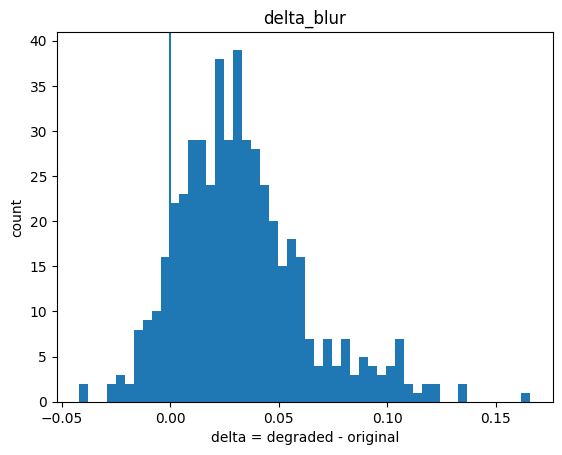

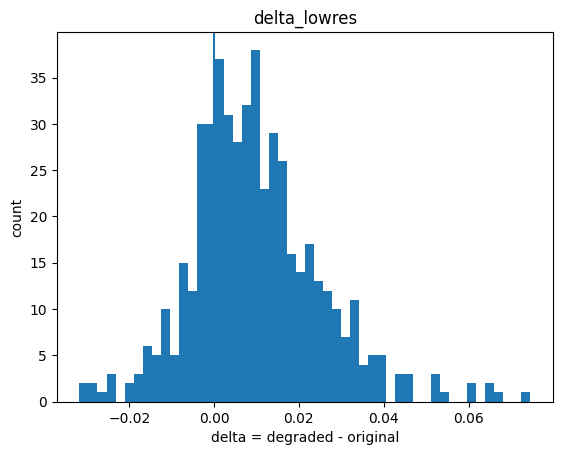

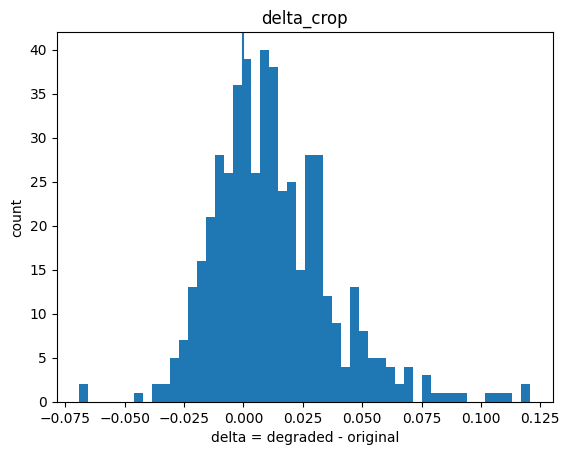

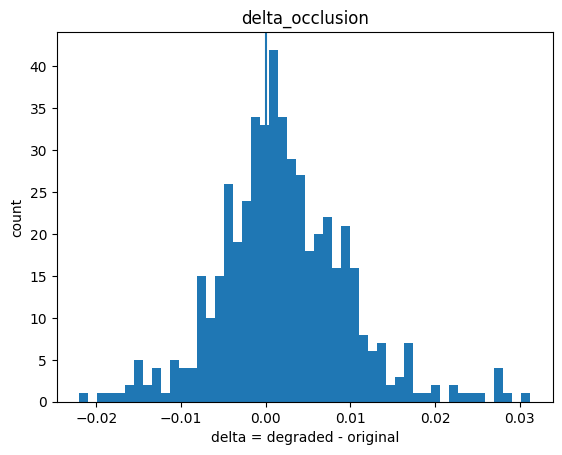

In [26]:
import matplotlib.pyplot as plt

for c in delta_cols:
    plt.figure()
    plt.hist(df[c].values, bins=50)
    plt.title(c)
    plt.xlabel("delta = degraded - original")
    plt.ylabel("count")
    plt.axvline(0)
    plt.show()


In [27]:
df.to_csv("disagreement_results_500.csv", index=False)
print("Saved: disagreement_results_500.csv")


Saved: disagreement_results_500.csv


In [28]:
import random
import numpy as np

random.seed(42)
np.random.seed(42)

def make_swapped_caption(df):
    captions = df["caption"].tolist()
    shuffled = captions.copy()
    random.shuffle(shuffled)

    # ensure not same caption by chance (rare but handle)
    swapped = []
    for orig, shuf in zip(captions, shuffled):
        if orig == shuf:
            # pick another random one
            shuf = captions[random.randrange(len(captions))]
        swapped.append(shuf)

    df2 = df.copy()
    df2["caption_swapped"] = swapped
    return df2

df2 = make_swapped_caption(df)
df2[["caption", "caption_swapped"]].head()


,caption,caption_swapped
0,a very typical bus station,"a couple years ago , i got this tattoo so i co..."
1,sierra looked stunning in this top and this sk...,carved stone animals on a public fountain
2,interior design of modern living room with fir...,paths are clearly marked with signs like this .
3,cybernetic scene isolated on white background .,illustration of a pattern with funny abstract ...
4,the jetty : different types of plants to estab...,"according to the model , she regularly gets to..."


In [29]:
def disagreement_image_with_text(img, text):
    E_img = get_image_embedding(img)
    E_txt = get_text_embedding(text)
    return cosine_distance(E_img, E_txt)

# We'll recompute using the same original images by reloading from URL.
# Store original image for each row first to avoid repeated downloads if you want speed,
# but here's the simple clean version:

wrong_scores = []
ok_scores = []
skipped = 0

for _, row in tqdm(df2.iterrows(), total=len(df2)):
    img = load_image_from_url(row["image_url"])
    if img is None:
        skipped += 1
        continue
    img = img.convert("RGB")

    ok = disagreement_image_with_text(img, row["caption"])
    wrong = disagreement_image_with_text(img, row["caption_swapped"])

    ok_scores.append(ok)
    wrong_scores.append(wrong)

print("Computed:", len(ok_scores), "Skipped:", skipped)
print("Mean ok:", np.mean(ok_scores), "Mean wrong:", np.mean(wrong_scores))


100%|██████████| 500/500 [01:31<00:00,  5.47it/s]

Computed: 500 Skipped: 0
Mean ok: 0.7084345703125 Mean wrong: 0.8452057876586914


In [30]:
!pip -q install scikit-learn
from sklearn.metrics import roc_auc_score

y_true = [0]*len(ok_scores) + [1]*len(wrong_scores)   # 0=correct, 1=wrong
y_score = ok_scores + wrong_scores                    # higher = more "wrong"

auc = roc_auc_score(y_true, y_score)
print("AUROC (correct vs swapped-wrong):", auc)


AUROC (correct vs swapped-wrong): 0.988132


In [31]:
import random
from PIL import ImageDraw

def occlusion(img, occ_ratio=0.5):  # increase from 0.3 → 0.5
    img = img.copy()
    w, h = img.size
    ow, oh = int(w*occ_ratio), int(h*occ_ratio)
    x0 = random.randint(0, max(0, w - ow))
    y0 = random.randint(0, max(0, h - oh))
    draw = ImageDraw.Draw(img)
    draw.rectangle([x0, y0, x0+ow, y0+oh], fill=(0, 0, 0))
    return img


In [32]:
def gaussian_blur(img, radius=8):   # from 5 → 8
    return img.filter(ImageFilter.GaussianBlur(radius))


In [33]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1) Build matrix of original image embeddings you already computed indirectly.
# We'll recompute embeddings for df images once and store them.

embs = []
valid_rows = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    img = load_image_from_url(row["image_url"])
    if img is None:
        continue
    img = img.convert("RGB")
    E = get_image_embedding(img).numpy().astype("float32").squeeze()
    embs.append(E)
    valid_rows.append(row)

embs = np.vstack(embs)
dfv = pd.DataFrame(valid_rows).reset_index(drop=True)

# 2) Find nearest neighbors
nn = NearestNeighbors(n_neighbors=6, metric="cosine").fit(embs)
dist, idx = nn.kneighbors(embs)

# 3) Swap captions with a near neighbor (not itself)
swapped_caps = []
for i in range(len(dfv)):
    # pick a random neighbor among top-5 (excluding itself at idx[i][0])
    j = np.random.choice(idx[i][1:6])
    swapped_caps.append(dfv.loc[j, "caption"])

dfv["caption_swapped_near"] = swapped_caps
dfv[["caption", "caption_swapped_near"]].head()


100%|██████████| 500/500 [00:51<00:00,  9.62it/s]


,caption,caption_swapped_near
0,a very typical bus station,students in front of a school
1,sierra looked stunning in this top and this sk...,i could see something like this for your hair ...
2,interior design of modern living room with fir...,color good with green couch in living room ......
3,cybernetic scene isolated on white background .,basic font for flat white icon in the orange c...
4,the jetty : different types of plants to estab...,could make the hallway to the master suite all...


In [34]:
ok_scores = []
wrong_scores = []
skipped = 0

for _, row in tqdm(dfv.iterrows(), total=len(dfv)):
    img = load_image_from_url(row["image_url"])
    if img is None:
        skipped += 1
        continue
    img = img.convert("RGB")

    ok = disagreement_image_with_text(img, row["caption"])
    wrong = disagreement_image_with_text(img, row["caption_swapped_near"])

    ok_scores.append(ok)
    wrong_scores.append(wrong)

from sklearn.metrics import roc_auc_score
auc_near = roc_auc_score([0]*len(ok_scores) + [1]*len(wrong_scores),
                         ok_scores + wrong_scores)
print("AUROC (correct vs near-swapped):", auc_near)


100%|██████████| 500/500 [01:46<00:00,  4.68it/s]

AUROC (correct vs near-swapped): 0.9228318898082291


In [35]:
import re
import random

# Tiny word bank (you can expand later)
swap_map = {
    "dog": "cat", "cat": "dog",
    "man": "woman", "woman": "man",
    "boy": "girl", "girl": "boy",
    "car": "bus", "bus": "car",
    "bicycle": "motorcycle", "motorcycle": "bicycle",
    "red": "blue", "blue": "red",
    "black": "white", "white": "black"
}

def minimally_edit_caption(caption):
    words = re.findall(r"\w+|\W+", caption)
    # try replace one word
    for _ in range(10):
        i = random.randrange(len(words))
        w = words[i].lower()
        if w in swap_map:
            repl = swap_map[w]
            # preserve case roughly
            words[i] = repl.capitalize() if words[i][0].isupper() else repl
            return "".join(words)
    return None  # couldn't edit

df2 = df.copy()
df2["caption_edit"] = df2["caption"].apply(minimally_edit_caption)
df2 = df2.dropna(subset=["caption_edit"]).reset_index(drop=True)
df2[["caption","caption_edit"]].head()


,caption,caption_edit
0,a very typical bus station,a very typical car station
1,cybernetic scene isolated on white background .,cybernetic scene isolated on black background .
2,safe deposit with money around it on a white b...,safe deposit with money around it on a black b...
3,portrait of a smiling woman stroking her dog l...,portrait of a smiling woman stroking her cat l...
4,the sign promises as much as the glorious blue...,the sign promises as much as the glorious red ...


In [36]:
ok_scores = []
wrong_scores = []
skipped = 0

for _, row in tqdm(df2.iterrows(), total=len(df2)):
    img = load_image_from_url(row["image_url"])
    if img is None:
        skipped += 1
        continue
    img = img.convert("RGB")

    ok = disagreement_image_with_text(img, row["caption"])
    wrong = disagreement_image_with_text(img, row["caption_edit"])

    ok_scores.append(ok)
    wrong_scores.append(wrong)

auc_edit = roc_auc_score([0]*len(ok_scores) + [1]*len(wrong_scores),
                         ok_scores + wrong_scores)
print("AUROC (correct vs minimally-edited):", auc_edit)
print("Edited samples:", len(ok_scores), "Skipped:", skipped)


100%|██████████| 65/65 [00:07<00:00,  8.91it/s]

AUROC (correct vs minimally-edited): 0.6379881656804733
Edited samples: 65 Skipped: 0


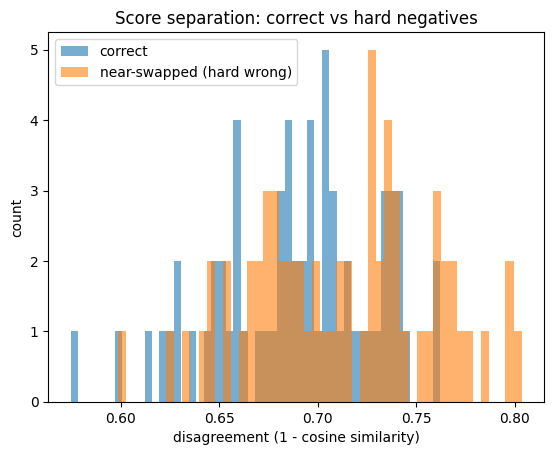

Means: 0.6884596604567308 0.7121469350961539
Medians: 0.693359375 0.714599609375


In [37]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.hist(ok_scores, bins=50, alpha=0.6, label="correct")
plt.hist(wrong_scores, bins=50, alpha=0.6, label="near-swapped (hard wrong)")
plt.xlabel("disagreement (1 - cosine similarity)")
plt.ylabel("count")
plt.legend()
plt.title("Score separation: correct vs hard negatives")
plt.show()

print("Means:", np.mean(ok_scores), np.mean(wrong_scores))
print("Medians:", np.median(ok_scores), np.median(wrong_scores))
